# COGS 109 Checkpoint 2 | Member 2: Riley Ramos | Elastic net logistic regression
**Question:** Which pre-draft measurements predict whether a player scores above the median NBA PPG (5.65) in their first three post-combine seasons?

**My method:** Elastic net logistic regression. Thomas Ton uses forward stepwise selection and Ishaan Tibdewal uses lasso logistic regression.

Everyone uses the same data, train/test split, binary outcome, 5 CV folds and 24 candidate predictors. Only the selection method is different.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs('reports', exist_ok=True)

## Step 1: Load the data and make the binary outcome

In [2]:
features = pd.read_csv('../data/predraft_features.csv')
outcomes = pd.read_csv('../data/nba_outcomes.csv')

# same sample as Checkpoint 1: players matched to NCAA stats
df = features.merge(outcomes[['player_id', 'ppg_3yr']], on='player_id')
df = df[df.ncaa_match_status == 'matched'].reset_index(drop=True)
print('n =', len(df))

n = 770


In [3]:
# same 80/20 split as Checkpoint 1
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=42,
                                       stratify=df.position_group)
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
print('Train:', len(train), '| Test:', len(test))

Train: 616 | Test: 154


No natural cutoff exists for NBA PPG, so we use the training median. This splits the classes 50/50.

In [4]:
# 1 = scored more than the training median, 0 = at or below it
threshold = train.ppg_3yr.median()
y_train = (train.ppg_3yr > threshold).astype(int).values
y_test = (test.ppg_3yr > threshold).astype(int).values

print('Threshold:', round(threshold, 2), 'PPG')
print('Proportion of 1s in train:', round(y_train.mean(), 3))
print('Proportion of 1s in test:', round(y_test.mean(), 3))

Threshold: 5.65 PPG
Proportion of 1s in train: 0.5
Proportion of 1s in test: 0.5


## Step 2: Candidate predictors and CV folds
- 10 combine measurements and 11 NCAA stats (quantitative).
- `skipped_drills`: 1 if the player has no agility, sprint or vertical result. Top prospects often skip the drills, so filling those blanks with the median would hide this.
- Position: 2 dummies, baseline Guard.
- That is 24 predictors with n = 616 training players. IDs, names, team and years are left out.
- CV error = proportion of validation players misclassified (0.5 cutoff), averaged over 5 folds.

In [5]:
combine = ['height_in', 'weight_lb', 'wingspan_in', 'standing_reach_in', 'vertical_max_in',
           'vertical_standing_in', 'sprint_sec', 'agility_sec', 'bench_reps', 'body_fat_pct']
ncaa = ['ncaa_games', 'ncaa_mpg', 'ncaa_ppg', 'ncaa_apg', 'ncaa_rpg', 'ncaa_spg', 'ncaa_bpg',
        'ncaa_tov_pg', 'ncaa_fg_pct', 'ncaa_3p_pct', 'ncaa_ft_pct']

for d in [train, test]:
    # position dummies (baseline = Guard)
    d['pos_Forward'] = (d.position_group == 'Forward').astype(int)
    d['pos_Center'] = (d.position_group == 'Center').astype(int)
    # 1 = skipped the athletic drills (no agility, sprint or vertical result)
    drills = d[['agility_sec', 'sprint_sec', 'vertical_max_in']]
    d['skipped_drills'] = drills.isna().all(axis=1).astype(int)

predictors = combine + ncaa + ['skipped_drills', 'pos_Forward', 'pos_Center']
print('Number of predictors:', len(predictors))

# fill missing values with the TRAINING median (never look at the test set)
X_train = train[predictors].reset_index(drop=True)
X_test = test[predictors].reset_index(drop=True)
for col in predictors:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

skipped = X_train.skipped_drills == 1
print('Proportion of 1s | skipped drills:', round(y_train[skipped].mean(), 2),
      '| did drills:', round(y_train[~skipped].mean(), 2))

Number of predictors: 24
Proportion of 1s | skipped drills: 0.65 | did drills: 0.47


In [6]:
# 5 folds of the training set, the same for everyone
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))


def cv_error(model, cols):
    # misclassification rate on each validation fold, then the average and its standard error
    errors = []
    for fit_idx, val_idx in folds:
        model.fit(X_train.loc[fit_idx, cols], y_train[fit_idx])
        pred = model.predict(X_train.loc[val_idx, cols])
        errors.append(np.mean(pred != y_train[val_idx]))
    return np.mean(errors), np.std(errors, ddof=1) / np.sqrt(len(errors))


def fit_logit(cols):
    # ordinary logistic regression on the whole training set (gives AIC, BIC, p-values)
    X = sm.add_constant(X_train[cols], has_constant='add')
    return sm.Logit(y_train, X).fit(disp=0)


# plain logistic regression for CV (scaling only helps the solver, predictions are the same)
plain_logistic = make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=5000))

## Step 3: Elastic net
Elastic net mixes the lasso and ridge penalties. This helps here because some predictors are strongly correlated (height, wingspan, standing reach). Predictors are standardized so the penalty treats them equally. CV picks both the mix and λ.

In [7]:
lambdas = np.logspace(-1, 2, 40)   # penalty strength λ (sklearn uses C = 1/λ)
mixes = [0.2, 0.5, 0.8]            # l1_ratio: 1 = pure lasso, 0 = pure ridge

grid = []
for mix in mixes:
    for lam in lambdas:
        model = make_pipeline(StandardScaler(),
                              LogisticRegression(penalty='elasticnet', l1_ratio=mix, C=1 / lam,
                                                 solver='saga', max_iter=20000))
        err, se = cv_error(model, predictors)
        model.fit(X_train, y_train)
        coefs = model[-1].coef_[0]   # [-1] is the logistic regression step of the pipeline
        grid.append({'mix': mix, 'lambda': lam, 'cv_error': err, 'se': se,
                     'n_kept': np.sum(coefs != 0), 'coefs': coefs})

grid = pd.DataFrame(grid)
print(grid[['mix', 'lambda', 'cv_error', 'n_kept']].round(3).to_string(index=False))

 mix  lambda  cv_error  n_kept
 0.2   0.100     0.430      24
 0.2   0.119     0.430      24
 0.2   0.143     0.430      24
 0.2   0.170     0.430      24
 0.2   0.203     0.430      24
 0.2   0.242     0.430      24
 0.2   0.289     0.430      24
 0.2   0.346     0.430      24
 0.2   0.412     0.432      24
 0.2   0.492     0.432      24
 0.2   0.588     0.432      24
 0.2   0.702     0.432      24
 0.2   0.838     0.433      24
 0.2   1.000     0.432      23
 0.2   1.194     0.430      23
 0.2   1.425     0.425      23
 0.2   1.701     0.422      23
 0.2   2.031     0.424      23
 0.2   2.424     0.424      23
 0.2   2.894     0.422      23
 0.2   3.455     0.429      23
 0.2   4.125     0.430      23
 0.2   4.924     0.432      22
 0.2   5.878     0.430      22
 0.2   7.017     0.430      21
 0.2   8.377     0.425      21
 0.2  10.000     0.429      21
 0.2  11.938     0.427      21
 0.2  14.251     0.437      20
 0.2  17.013     0.433      18
 0.2  20.309     0.442      17
 0.2  24

In [8]:
# pick the mix and λ with the lowest CV error
best = grid.loc[grid.cv_error.idxmin()]
final_predictors = [var for var, c in zip(predictors, best.coefs) if c != 0]

print('Chosen mix:', best.mix, '| λ =', round(best['lambda'], 3), '| CV error =', round(best.cv_error, 3))
print('Kept', len(final_predictors), 'of', len(predictors), 'predictors:', final_predictors)

Chosen mix: 0.2 | λ = 1.701 | CV error = 0.422
Kept 23 of 24 predictors: ['height_in', 'weight_lb', 'wingspan_in', 'standing_reach_in', 'vertical_max_in', 'vertical_standing_in', 'sprint_sec', 'agility_sec', 'bench_reps', 'body_fat_pct', 'ncaa_games', 'ncaa_mpg', 'ncaa_ppg', 'ncaa_rpg', 'ncaa_spg', 'ncaa_bpg', 'ncaa_tov_pg', 'ncaa_fg_pct', 'ncaa_3p_pct', 'ncaa_ft_pct', 'skipped_drills', 'pos_Forward', 'pos_Center']


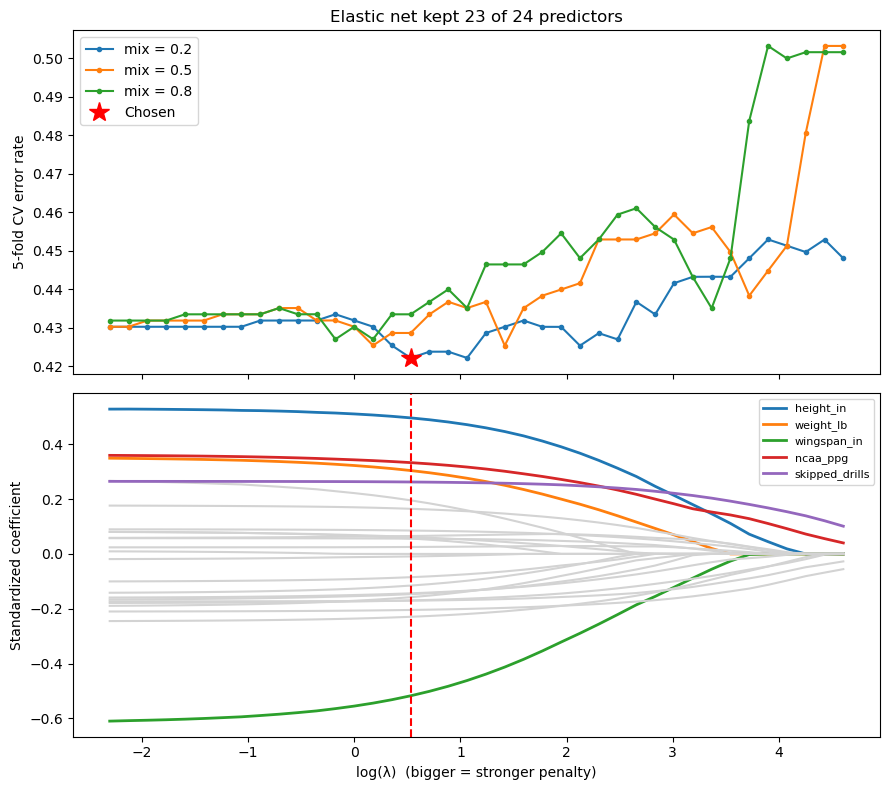

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

for mix in mixes:
    rows = grid[grid.mix == mix]
    axs[0].plot(np.log(rows['lambda']), rows.cv_error, marker='o', markersize=3, label=f'mix = {mix}')
axs[0].plot(np.log(best['lambda']), best.cv_error, 'r*', markersize=15, label='Chosen')
axs[0].set(ylabel='5-fold CV error rate',
           title=f'Elastic net kept {len(final_predictors)} of {len(predictors)} predictors')
axs[0].legend()

# coefficient paths for the chosen mix; the 5 biggest coefficients are labeled
rows = grid[grid.mix == best.mix]
paths = np.array(rows.coefs.tolist())
top5 = np.argsort(-np.abs(best.coefs))[:5]
for i, var in enumerate(predictors):
    if i in top5:
        axs[1].plot(np.log(rows['lambda']), paths[:, i], linewidth=2, label=var)
    else:
        axs[1].plot(np.log(rows['lambda']), paths[:, i], color='lightgrey')
axs[1].axvline(np.log(best['lambda']), color='red', linestyle='--')
axs[1].set(xlabel='log(λ)  (bigger = stronger penalty)', ylabel='Standardized coefficient')
axs[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('reports/elasticnet_cv_plot.png', dpi=150)
plt.show()

**TODO (Riley):** Which mix and λ did CV pick? How many predictors were kept?

## Step 4: Selected model
For lasso and elastic net, the kept predictors are refit as an ordinary logistic regression. Odds ratio = e^β: how the odds of being an above-median scorer change for a 1-unit increase in a predictor, holding the others fixed.

In [10]:
final = fit_logit(final_predictors)
cv, se = cv_error(plain_logistic, final_predictors)

print('Predictors:', len(final_predictors))
print('AIC:', round(final.aic, 1))
print('BIC:', round(final.bic, 1))
print('CV error rate:', round(cv, 3))

Predictors: 23
AIC: 842.9
BIC: 949.1
CV error rate: 0.433


In [11]:
table = pd.DataFrame({'coef': final.params,
                      'odds_ratio': np.exp(final.params),
                      'p_value': final.pvalues})
# standardized coefficient = change in log-odds for a 1 SD increase (lets us compare predictors)
table['std_coef'] = table.coef * X_train[final_predictors].std()
table = table.sort_values('std_coef', key=abs, ascending=False)
print(table.round(3))

                       coef  odds_ratio  p_value  std_coef
wingspan_in          -0.161       0.851    0.010    -0.617
height_in             0.168       1.182    0.046     0.530
ncaa_ppg              0.092       1.096    0.011     0.359
weight_lb             0.015       1.015    0.045     0.352
standing_reach_in     0.057       1.058    0.432     0.269
skipped_drills        0.692       1.998    0.003     0.265
bench_reps           -0.062       0.940    0.012    -0.246
agility_sec          -0.440       0.644    0.042    -0.211
pos_Center           -0.655       0.519    0.201    -0.191
ncaa_3p_pct          -0.016       0.984    0.056    -0.179
ncaa_spg              0.345       1.412    0.099     0.179
sprint_sec           -1.465       0.231    0.155    -0.173
ncaa_mpg             -0.037       0.964    0.246    -0.165
body_fat_pct         -0.066       0.936    0.147    -0.160
pos_Forward          -0.291       0.748    0.333    -0.144
ncaa_rpg             -0.044       0.957    0.494    -0.1

In [12]:
b = final.params
equation = 'log(p / (1 - p)) = ' + str(round(b['const'], 3))
for var in final_predictors:
    coef = round(b[var], 3)
    if coef >= 0:
        equation += f' + {coef}*{var}'
    else:
        equation += f' - {abs(coef)}*{var}'

print(f'p = P(NBA PPG > {threshold:.2f})')
print(equation)

p = P(NBA PPG > 5.65)
log(p / (1 - p)) = -0.295 + 0.168*height_in + 0.015*weight_lb - 0.161*wingspan_in + 0.057*standing_reach_in + 0.007*vertical_max_in + 0.03*vertical_standing_in - 1.465*sprint_sec - 0.44*agility_sec - 0.062*bench_reps - 0.066*body_fat_pct + 0.017*ncaa_games - 0.037*ncaa_mpg + 0.092*ncaa_ppg - 0.044*ncaa_rpg + 0.345*ncaa_spg + 0.096*ncaa_bpg - 0.022*ncaa_tov_pg + 0.009*ncaa_fg_pct - 0.016*ncaa_3p_pct + 0.006*ncaa_ft_pct + 0.692*skipped_drills - 0.291*pos_Forward - 0.655*pos_Center


**TODO (Riley):** Interpret at least two odds ratios. Example: "each extra college point per game multiplies the odds of being an above-median NBA scorer by 1.07 (7% higher odds)". For position, name the baseline (Guard).

## Step 5: Test the model once
Predict 1 if the probability is above 0.5. The baseline always predicts the most common training class.

In [13]:
X_test_const = sm.add_constant(X_test[final_predictors], has_constant='add')
prob = final.predict(X_test_const)
pred = (prob > 0.5).astype(int)

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
auc = roc_auc_score(y_test, prob)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

# baseline: always predict the most common class in the training set
majority = 1 if y_train.mean() >= 0.5 else 0
baseline = np.mean(y_test == majority)

print('Test accuracy:', round(accuracy, 3), '| baseline:', round(baseline, 3))
print('Precision:', round(precision, 3), '| Recall:', round(recall, 3), '| AUC:', round(auc, 3))
print('TP:', tp, '| FP:', fp, '| TN:', tn, '| FN:', fn)

Test accuracy: 0.649 | baseline: 0.5
Precision: 0.653 | Recall: 0.636 | AUC: 0.689
TP: 49 | FP: 26 | TN: 51 | FN: 28


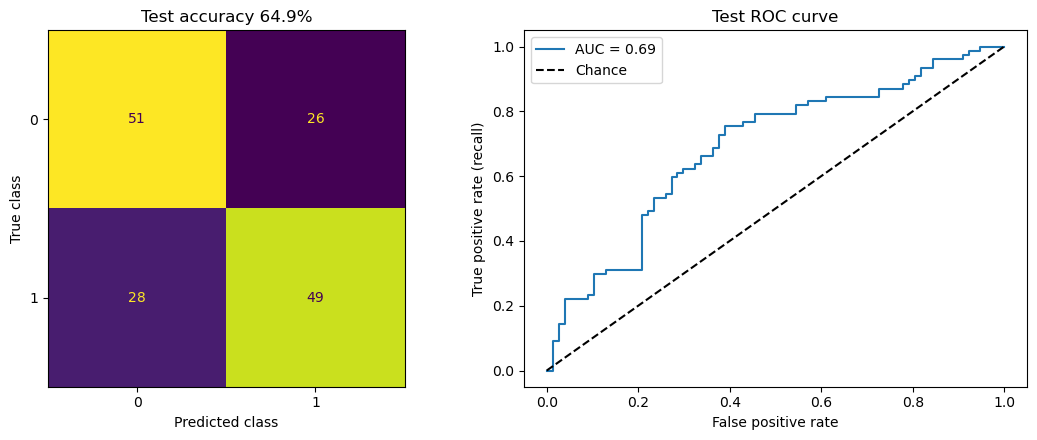

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axs[0], colorbar=False)
axs[0].set(xlabel='Predicted class', ylabel='True class', title=f'Test accuracy {accuracy:.1%}')

fpr, tpr, _ = roc_curve(y_test, prob)
axs[1].plot(fpr, tpr, label=f'AUC = {auc:.2f}')
axs[1].plot([0, 1], [0, 1], 'k--', label='Chance')
axs[1].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='Test ROC curve')
axs[1].legend()

plt.tight_layout()
plt.savefig('reports/elasticnet_test.png', dpi=150)
plt.show()

**TODO (Riley):** Interpret the AUC in one sentence: "for a random above-median and below-median scorer, the model gives the above-median scorer the higher probability X% of the time." Does the model beat the baseline?

In [15]:
# save results for the group comparison notebook
results = pd.DataFrame([{'member': 'Riley Ramos', 'method': 'Elastic net logistic regression',
                         'n_predictors': len(final_predictors), 'predictors': ', '.join(final_predictors),
                         'cv_error': cv, 'aic': final.aic, 'bic': final.bic,
                         'accuracy': accuracy, 'auc': auc, 'precision': precision, 'recall': recall,
                         'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn, 'baseline': baseline}])
results.to_csv('reports/elasticnet_results.csv', index=False)
pd.DataFrame({'fpr': fpr, 'tpr': tpr}).to_csv('reports/elasticnet_roc.csv', index=False)

## Conclusion

**TODO (Riley):** 3-4 bullets: predictors kept, AIC/BIC/CV error, test accuracy vs baseline, AUC.